# CyberMind: generación y verificación del dataset sintético

Este cuaderno reúne en un solo lugar lo que antes eran dos scripts (`generar_dataset.py` y `verificar_dataset.py`):

| # | Sección | Qué hace |
|---|---|---|
| 1 | Parámetros | Número de estudiantes y semilla |
| 2 | Generador | Cómo se simula cada estudiante, sus respuestas y la decisión correcta |
| 3 | Generar y guardar | Crea el dataset y lo escribe en dos CSV |
| 4 | Revisión de columnas | Comprueba que el dataset tiene exactamente las variables previstas |
| 5 | Verificación | Comprueba que la etiqueta se puede aprender y que no es trivial |

**Qué representa una fila:** un par (estudiante, tema), tal como el servicio de IA lo recibiría después de la evaluación diagnóstica, más la decisión que debería tomar: **REFUERZO** o **AVANCE**.

**Variables de entrada (8):** `tema`, `experiencia_previa`, `aciertos_basico`, `aciertos_intermedio`, `aciertos_avanzado`, `puntaje_tema`, `puntaje_global` y `tiempo_promedio_seg`. La confianza autorreportada ya no forma parte del dataset.

> Los datos son **sintéticos**: validan el procedimiento, no la efectividad pedagógica con estudiantes reales.

## 1. Parámetros

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

N_ESTUDIANTES = 1500   # cada estudiante aporta 5 filas (una por tema)
SEMILLA = 42           # con la misma semilla se obtiene exactamente el mismo dataset
CARPETA_SALIDA = Path.cwd().parent / "data" if (Path.cwd().parent / "data").is_dir() else Path.cwd()   # repo: ../data; en Colab: /content

## 2. Generador

El dataset se construye en tres capas:

1. **Variables latentes (no observables):** cada estudiante simulado tiene una experiencia previa (ninguna, cursos o laboral), una habilidad general y un **dominio real por tema** (`theta`). Un estudiante real nunca revela estos valores.
2. **Variables observables:** las respuestas al diagnóstico se simulan con un modelo de **Teoría de Respuesta al Ítem de 3 parámetros (3PL)**: la probabilidad de acertar depende del dominio del estudiante, de la dificultad de la pregunta y de la probabilidad de acertar al azar (0,25 con 4 opciones). Se añaden tiempos de respuesta (el 4 % de los estudiantes responde al azar y muy rápido). **Son las únicas variables que el modelo puede usar.**
3. **Etiqueta:** **AVANCE** si la probabilidad de aprobar la unidad siguiente, calculada con el dominio real, es de al menos 0,70; si no, **REFUERZO**. Después se invierte un 5 % de las etiquetas para simular desacuerdo entre evaluadores.

Los parámetros del generador (dificultad de temas, proporciones de experiencia, umbral de 0,70, nivel de ruido) son **supuestos declarados**, no mediciones.

In [2]:
TEMAS = {
    # tema: dificultad relativa del tema (escala logit; >0 = más difícil)
    "fundamentos_redes": -0.30,
    "criptografia": 0.40,
    "seguridad_web": 0.30,
    "ingenieria_social": -0.50,
    "gestion_vulnerabilidades": 0.20,
}

EXPERIENCIA = {
    # nivel: (proporción en la población, media de habilidad general)
    "ninguna": (0.50, -0.50),
    "cursos": (0.35, 0.30),
    "laboral": (0.15, 0.90),
}

# Ítems del diagnóstico por tema: 3 por nivel, con su dificultad base (logit)
NIVELES_ITEM = {"basico": -1.0, "intermedio": 0.0, "avanzado": 1.0}
ITEMS_POR_NIVEL = 3
DISCRIMINACION = 1.2      # parámetro a del modelo 3PL
ADIVINANZA = 0.25         # parámetro c: preguntas de 4 opciones
D = 1.7                   # constante de escala de la IRT

UMBRAL_DOMINIO = 0.70     # probabilidad mínima de aprobar para recomendar AVANCE
DIFICULTAD_UNIDAD = 0.0   # la unidad siguiente es de nivel intermedio
RUIDO_ETIQUETA = 0.05     # fracción de etiquetas invertidas
PROP_ADIVINADORES = 0.04  # estudiantes que responden al azar y rápido


def sigmoide(x):
    return 1.0 / (1.0 + np.exp(-x))


def generar(n_estudiantes: int, semilla: int):
    rng = np.random.default_rng(semilla)
    temas = list(TEMAS)
    n_temas = len(temas)

    # --- Capa 1: latentes por estudiante ---------------------------------
    niveles = list(EXPERIENCIA)
    probs = [EXPERIENCIA[k][0] for k in niveles]
    experiencia = rng.choice(niveles, size=n_estudiantes, p=probs)
    media_g = np.array([EXPERIENCIA[e][1] for e in experiencia])
    habilidad_general = rng.normal(media_g, 0.8)
    adivinador = rng.random(n_estudiantes) < PROP_ADIVINADORES

    # Dominio real por tema: mezcla de habilidad general y variación propia
    theta = 0.75 * habilidad_general[:, None] + rng.normal(0, 0.65, (n_estudiantes, n_temas))
    dif_tema = np.array([TEMAS[t] for t in temas])

    # --- Capa 2: observables del diagnóstico ------------------------------
    aciertos = {}
    for nivel, b in NIVELES_ITEM.items():
        p = ADIVINANZA + (1 - ADIVINANZA) * sigmoide(
            D * DISCRIMINACION * (theta - b - dif_tema[None, :])
        )
        p = np.where(adivinador[:, None], ADIVINANZA, p)
        aciertos[nivel] = rng.binomial(ITEMS_POR_NIVEL, p)

    total_items = ITEMS_POR_NIVEL * len(NIVELES_ITEM)
    puntaje_tema = sum(aciertos.values()) / total_items * 100
    puntaje_global = puntaje_tema.mean(axis=1, keepdims=True).repeat(n_temas, axis=1)

    # Tiempo medio por pregunta (s): log-normal, algo menor con más dominio;
    # los adivinadores responden muy rápido
    tiempo = 45 * np.exp(-0.15 * theta + rng.normal(0, 0.35, theta.shape))
    tiempo = np.where(adivinador[:, None], rng.uniform(4, 10, theta.shape), tiempo)
    tiempo = np.clip(tiempo, 3, 180)


    # --- Capa 3: etiqueta --------------------------------------------------
    p_aprobar = sigmoide(D * DISCRIMINACION * (theta - DIFICULTAD_UNIDAD - dif_tema[None, :]))
    decision_limpia = np.where(p_aprobar >= UMBRAL_DOMINIO, "AVANCE", "REFUERZO")
    invertir = rng.random(theta.shape) < RUIDO_ETIQUETA
    decision = np.where(
        invertir, np.where(decision_limpia == "AVANCE", "REFUERZO", "AVANCE"), decision_limpia
    )

    # --- Formato largo: una fila por (estudiante, tema) -------------------
    ids = np.array([f"E{i:05d}" for i in range(n_estudiantes)])
    filas = {
        "id_estudiante": ids.repeat(n_temas),
        "tema": np.tile(temas, n_estudiantes),
        "experiencia_previa": experiencia.repeat(n_temas),
        "aciertos_basico": aciertos["basico"].ravel(),
        "aciertos_intermedio": aciertos["intermedio"].ravel(),
        "aciertos_avanzado": aciertos["avanzado"].ravel(),
        "puntaje_tema": np.round(puntaje_tema.ravel(), 1),
        "puntaje_global": np.round(puntaje_global.ravel(), 1),
        "tiempo_promedio_seg": np.round(tiempo.ravel(), 1),
        "decision": decision.ravel(),
    }
    datos = pd.DataFrame(filas)

    oculto = pd.DataFrame({
        "id_estudiante": filas["id_estudiante"],
        "tema": filas["tema"],
        "habilidad_general": np.round(habilidad_general.repeat(n_temas), 4),
        "theta_dominio_real": np.round(theta.ravel(), 4),
        "p_aprobar_unidad": np.round(p_aprobar.ravel(), 4),
        "adivinador_rapido": adivinador.repeat(n_temas),
        "decision_sin_ruido": decision_limpia.ravel(),
        "etiqueta_invertida": invertir.ravel(),
    })
    return datos, oculto

## 3. Generar y guardar

Se escribe el archivo:

- `cybermind_sintetico.csv`: el dataset para entrenar y probar modelos (7.500 filas con la configuración por defecto).


In [3]:
datos, _ = generar(N_ESTUDIANTES, SEMILLA)
CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)
datos.to_csv(CARPETA_SALIDA / "cybermind_sintetico.csv", index=False)

print(f"Filas: {len(datos)} ({N_ESTUDIANTES} estudiantes x {len(TEMAS)} temas), semilla {SEMILLA}")
print("\nDistribución de la etiqueta:")
print(datos["decision"].value_counts(normalize=True).round(3).to_string())
print("\n% REFUERZO por tema:")
print((datos.groupby("tema")["decision"].apply(lambda s: (s == "REFUERZO").mean()) * 100).round(1).to_string())
datos.head()

Filas: 7500 (1500 estudiantes x 5 temas), semilla 42

Distribución de la etiqueta:
decision
REFUERZO    0.654
AVANCE      0.346

% REFUERZO por tema:
tema
criptografia                77.1
fundamentos_redes           55.1
gestion_vulnerabilidades    70.1
ingenieria_social           48.9
seguridad_web               75.9


,id_estudiante,tema,experiencia_previa,aciertos_basico,aciertos_intermedio,aciertos_avanzado,puntaje_tema,puntaje_global,tiempo_promedio_seg,decision
0,E00000,fundamentos_redes,cursos,3,2,0,55.6,73.3,44.9,AVANCE
1,E00000,criptografia,cursos,3,2,2,77.8,73.3,55.1,AVANCE
2,E00000,seguridad_web,cursos,3,3,2,88.9,73.3,31.7,REFUERZO
3,E00000,ingenieria_social,cursos,3,2,1,66.7,73.3,45.4,REFUERZO
4,E00000,gestion_vulnerabilidades,cursos,3,3,1,77.8,73.3,30.5,AVANCE


## 4. Revisión de columnas

Comprueba que el dataset tiene exactamente las columnas previstas y que no quedó ninguna variable de confianza autorreportada.

In [4]:
COLUMNAS_ESPERADAS = ["id_estudiante", "tema", "experiencia_previa", "aciertos_basico", "aciertos_intermedio",
                      "aciertos_avanzado", "puntaje_tema", "puntaje_global", "tiempo_promedio_seg", "decision"]
assert list(datos.columns) == COLUMNAS_ESPERADAS, list(datos.columns)
assert not any("confianza" in c for c in datos.columns)
assert datos.isna().sum().sum() == 0
print("Columnas correctas:", len(datos.columns), "| sin valores faltantes | sin variable de confianza")
datos.describe().T[["mean", "std", "min", "max"]]

Columnas correctas: 10 | sin valores faltantes | sin variable de confianza


,mean,std,min,max
aciertos_basico,2.371867,0.898344,0.0,3.0
aciertos_intermedio,1.799733,1.042835,0.0,3.0
aciertos_avanzado,1.220267,0.969059,0.0,3.0
puntaje_tema,59.914933,24.800063,0.0,100.0
puntaje_global,59.909067,17.285263,13.3,100.0
tiempo_promedio_seg,46.697413,20.475912,4.0,180.0


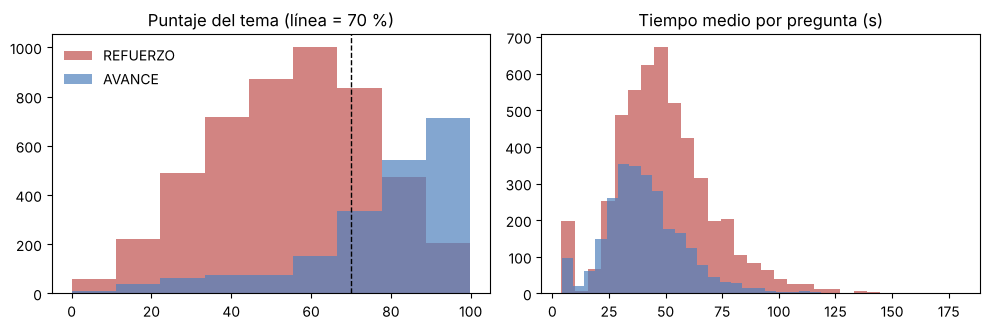

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for clase, color in [("REFUERZO", "#c0504d"), ("AVANCE", "#4f81bd")]:
    sub = datos[datos["decision"] == clase]
    ax[0].hist(sub["puntaje_tema"], bins=np.arange(0, 105, 11.1), alpha=.7, label=clase, color=color)
    ax[1].hist(sub["tiempo_promedio_seg"], bins=30, alpha=.7, label=clase, color=color)
ax[0].axvline(70, ls="--", c="k", lw=1); ax[0].set_title("Puntaje del tema (línea = 70 %)")
ax[1].set_title("Tiempo medio por pregunta (s)"); ax[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 5. Verificación del dataset

Comprueba que la etiqueta **se puede aprender** a partir de las variables observables y que **no es trivial**. No es el entrenamiento del modelo final.

- **Partición:** 75 % entrenamiento / 25 % prueba con `GroupShuffleSplit(random_state=0)`, agrupada por estudiante: las 5 filas de un estudiante quedan juntas, para evitar fuga de información.
- **Clase positiva:** REFUERZO.
- **Modelos comparados:**
  - *Regla fija:* AVANCE si `puntaje_tema` ≥ 70.
  - *Árbol de decisión:* `max_depth=4`, `min_samples_leaf=50`, `random_state=0`.
  - *Regresión logística:* `max_iter=1000`, el resto por defecto, con variables numéricas estandarizadas.


In [6]:
CATEGORICAS = ["tema", "experiencia_previa"]
NUMERICAS = ["aciertos_basico", "aciertos_intermedio", "aciertos_avanzado", "puntaje_tema",
             "puntaje_global", "tiempo_promedio_seg"]
X = datos[CATEGORICAS + NUMERICAS]
y = (datos["decision"] == "REFUERZO").astype(int)

ent, pru = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0).split(X, y, groups=datos["id_estudiante"]))
print(f"Entrenamiento: {len(ent)} filas | Prueba: {len(pru)} filas | % REFUERZO en prueba: {y.iloc[pru].mean():.1%}")

filas = []
def informe(nombre, pred):
    filas.append({"modelo": nombre, "exactitud": accuracy_score(y.iloc[pru], pred),
                  "F1": f1_score(y.iloc[pru], pred), "recall_REFUERZO": recall_score(y.iloc[pru], pred)})

informe("Regla puntaje_tema >= 70", (X.iloc[pru]["puntaje_tema"] < 70).astype(int))

arbol = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS)], remainder="passthrough",
                      verbose_feature_names_out=False),
    DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, random_state=0),
)
arbol.fit(X.iloc[ent], y.iloc[ent])
informe("Árbol de decisión (prof. 4)", arbol.predict(X.iloc[pru]))

logistica = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
                       ("num", StandardScaler(), NUMERICAS)]),
    LogisticRegression(max_iter=1000),
)
logistica.fit(X.iloc[ent], y.iloc[ent])
informe("Regresión logística", logistica.predict(X.iloc[pru]))

print(f"Exactitud de predecir siempre REFUERZO: {y.iloc[pru].mean():.3f}")
pd.DataFrame(filas).set_index("modelo").round(3)

Entrenamiento: 5625 filas | Prueba: 1875 filas | % REFUERZO en prueba: 67.6%
Exactitud de predecir siempre REFUERZO: 0.676


,exactitud,F1,recall_REFUERZO
modelo,,,
Regla puntaje_tema >= 70,0.813,0.862,0.866
Árbol de decisión (prof. 4),0.818,0.869,0.897
Regresión logística,0.825,0.874,0.899


In [7]:
print("Reglas aprendidas por el árbol (1 = REFUERZO):")
print(export_text(arbol[-1], feature_names=list(arbol[0].get_feature_names_out())))

Reglas aprendidas por el árbol (1 = REFUERZO):
|--- puntaje_tema <= 72.25
|   |--- puntaje_tema <= 61.15
|   |   |--- tiempo_promedio_seg <= 18.95
|   |   |   |--- experiencia_previa_ninguna <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- experiencia_previa_ninguna >  0.50
|   |   |   |   |--- class: 1
|   |   |--- tiempo_promedio_seg >  18.95
|   |   |   |--- puntaje_tema <= 50.00
|   |   |   |   |--- class: 1
|   |   |   |--- puntaje_tema >  50.00
|   |   |   |   |--- class: 1
|   |--- puntaje_tema >  61.15
|   |   |--- experiencia_previa_ninguna <= 0.50
|   |   |   |--- aciertos_avanzado <= 1.50
|   |   |   |   |--- class: 1
|   |   |   |--- aciertos_avanzado >  1.50
|   |   |   |   |--- class: 1
|   |   |--- experiencia_previa_ninguna >  0.50
|   |   |   |--- aciertos_avanzado <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- aciertos_avanzado >  0.50
|   |   |   |   |--- class: 1
|--- puntaje_tema >  72.25
|   |--- puntaje_tema <= 83.35
|   |   |--- puntaje_global <= 6

**Lectura:** la etiqueta es aprendible y no es trivial, y un modelo simple ya captura casi todo lo que estas variables permiten. Estas cifras validan el dataset, no el modelo final ni el efecto pedagógico.

El archivo generado (`data/cybermind_sintetico.csv`) es el que usa el cuaderno `02_pruebas_modelos.ipynb`.